# Icefield grid comparison at CLFG

Compare the cells containing CLFG in the native HRRR-AK grid and the 20, 50, 100, 250, 500, and 1,000 m downscaled grids. The site reference is a sample from the 2 m ArcticDEM, with no surveyed elevation in the site record. The CSV stores the cell elevation, elevation offset, and hypothetical temperature adjustment at 6 K/km. TopoPyScale already accounts for elevation, so use the residual as a diagnostic.

Grids appear as their terrain files become available. The hourly temperature map uses the forcing files that have finished.

In [1]:
from pathlib import Path
import sys
cwd = Path.cwd()
candidates = (cwd, cwd / "downscaling", cwd / "jif_snow_modeling" / "downscaling")
folder = next((path for path in candidates if (path / "icefield_comparison.py").is_file()), None)
if folder is None:
    raise FileNotFoundError(
        "Open this notebook from the repos workspace, jif_snow_modeling, or its downscaling folder."
    )
sys.path.insert(0, str(folder))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display
from icefield_comparison import RUN, RESOLUTIONS, edges, lookup, raw_geometry, raw_path, site

year = 2026
project = RUN / f"WY{year}"
output = folder / "outputs"
output.mkdir(exist_ok=True)
terrains = [project / f"{m}m/terrain.nc" for m in RESOLUTIONS]
forcings = [project / f"{m}m/forcing.nc" for m in RESOLUTIONS]
surface_path = project / "surface_native.nc"
from matplotlib.colors import Normalize
from matplotlib.patches import Polygon
from pyproj import Transformer
from icefield_comparison import ALASKA_GRID

lon, lat, east, north, reference = site()
panels = []
with xr.open_dataset(raw_path(year)) as raw:
    raw_x, raw_y = raw_geometry(raw)
    transformer = Transformer.from_crs(ALASKA_GRID, 32608, always_xy=True)
    x, y = transformer.transform(*np.meshgrid(edges(raw_x), edges(raw_y)))
    panels.append(("Native HRRR-AK", x, y, raw.orog.isel(time=0).values))
terrain_grids = {}
available = [m for m, path in zip(RESOLUTIONS, terrains) if path.exists()]
elevations = lookup(year, available)
if available:
    elevations.to_csv(output / f"clfg_resolution_test_elevations_WY{year}.csv")
    display(elevations[["row", "col", "cell_id", "elevation_m", "reference_elevation_m",
                       "cell_minus_reference_m", "hypothetical_6_K_km_adjustment_K"]].round(2))
    for m in available:
        path = project / f"{m}m/terrain.nc"
        with xr.open_dataset(path) as ds:
            x, y = np.meshgrid(edges(ds.x.values), edges(ds.y.values))
            panels.append((f"TopoPyScale {m} m", x, y, ds.elevation.values))
            terrain_grids[m] = ds.cell_id.values
else:
    print("Waiting for the first terrain grid.")


,row,col,cell_id,elevation_m,reference_elevation_m,cell_minus_reference_m,hypothetical_6_K_km_adjustment_K
grid,,,,,,,
Native HRRR-AK,12,10,-1,928.33,652.02,276.31,1.66
TopoPyScale 1000 m,2,3,15,711.36,652.02,59.34,0.36
TopoPyScale 500 m,5,6,66,652.98,652.02,0.96,0.01
TopoPyScale 250 m,11,12,276,650.06,652.02,-1.97,-0.01
TopoPyScale 100 m,29,30,1770,649.98,652.02,-2.04,-0.01
TopoPyScale 50 m,58,60,7020,651.41,652.02,-0.61,-0.00
TopoPyScale 20 m,145,150,43650,652.40,652.02,0.38,0.00


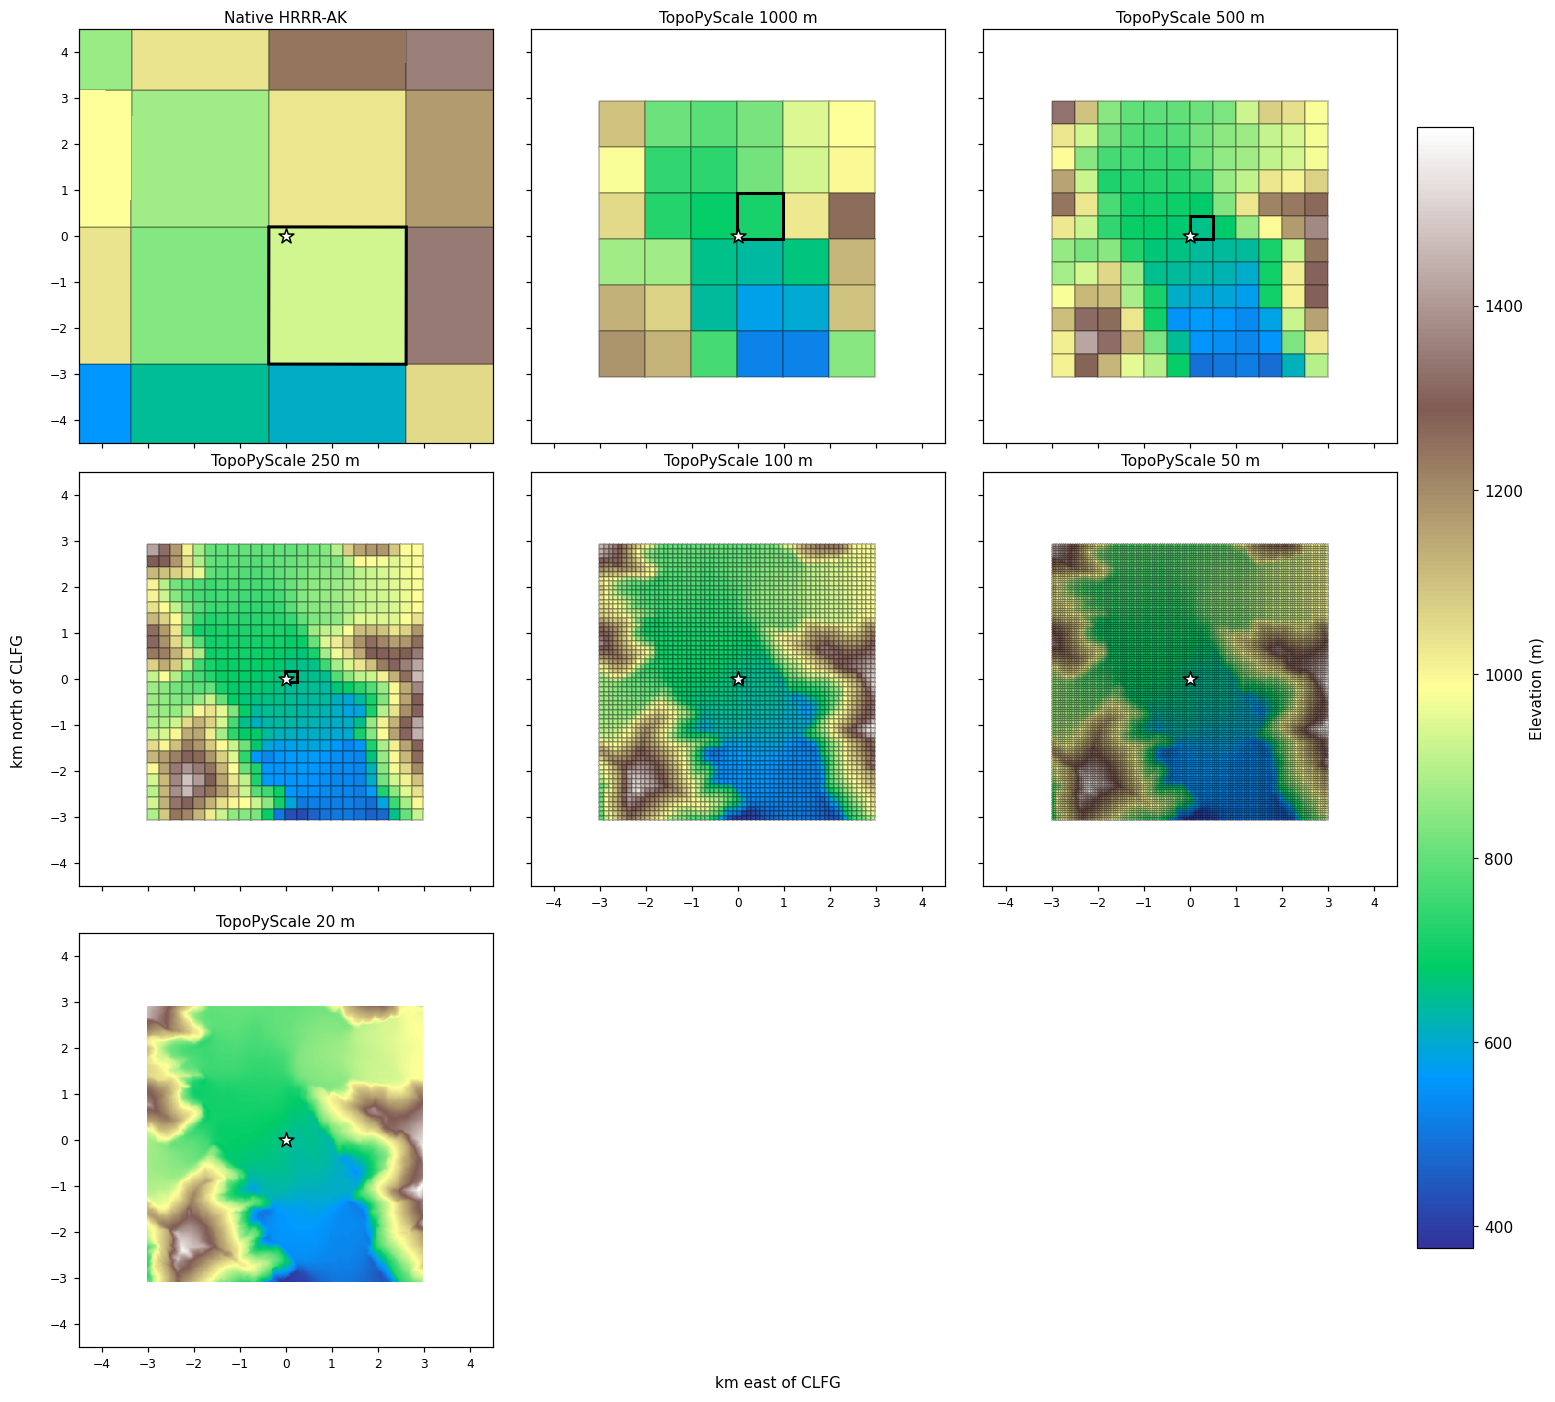

In [2]:
def map_panels(items, extent, colorbar=False):
    ncols = 3
    nrows = (len(items) + ncols - 1) // ncols
    west, east_limit, south, north_limit = extent
    panel_width = 3.7 if colorbar else 4
    panel_height = panel_width * (north_limit - south) / (east_limit - west)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(14 if colorbar else 13, nrows * (panel_height + .3) + .6),
        sharex=True, sharey=True, squeeze=False, layout="constrained",
        gridspec_kw={"wspace": .01, "hspace": .01},
    )
    fig.get_layout_engine().set(w_pad=.025, h_pad=.025)
    for i, ax in enumerate(axes.flat):
        if i >= len(items):
            ax.set_visible(False)
        else:
            ax.set(xlim=(west, east_limit), ylim=(south, north_limit), aspect="equal")
            ax.tick_params(labelbottom=i + ncols >= len(items), labelsize=8)
    fig.supxlabel("km east of CLFG", fontsize=10)
    fig.supylabel("km north of CLFG", fontsize=10)
    return fig, axes.ravel()[:len(items)]


def outline_site_cell(ax, label, x, y, **style):
    row, col = elevations.loc[label, ["row", "col"]].astype(int)
    corners = [(row, col), (row, col + 1), (row + 1, col + 1), (row + 1, col)]
    ax.add_patch(Polygon([(x[i, j], y[i, j]) for i, j in corners],
                         fill=False, **style))


def plot_maps(items, units, cmap="terrain", radius=4500):
    extent = (-radius / 1000, radius / 1000) * 2
    fig, axes = map_panels(items, extent, colorbar=True)
    local_values = []
    for _, x, y, values in items:
        near = (
            (abs(x[:-1, :-1] - east) < radius + 3000)
            & (abs(y[:-1, :-1] - north) < radius + 3000)
        )
        local_values.extend(values[near & np.isfinite(values)])
    norm = Normalize(min(local_values), max(local_values) + 1e-8)
    for ax, (label, x, y, values) in zip(axes, items):
        xx, yy = (x - east) / 1000, (y - north) / 1000
        image = ax.pcolormesh(xx, yy, values, cmap=cmap, norm=norm,
                             edgecolors=(0, 0, 0, .22) if values.size < 20000 else "none",
                             linewidth=.25)
        outline_site_cell(ax, label, xx, yy, edgecolor="black", linewidth=2)
        ax.scatter(0, 0, marker="*", s=105, facecolor="white", edgecolor="black", zorder=3)
        ax.set_title(label, fontsize=10, pad=4)
    fig.colorbar(image, ax=list(axes), label=units, shrink=.85, pad=.015)
    plt.show()


plot_maps(panels, "Elevation (m)")

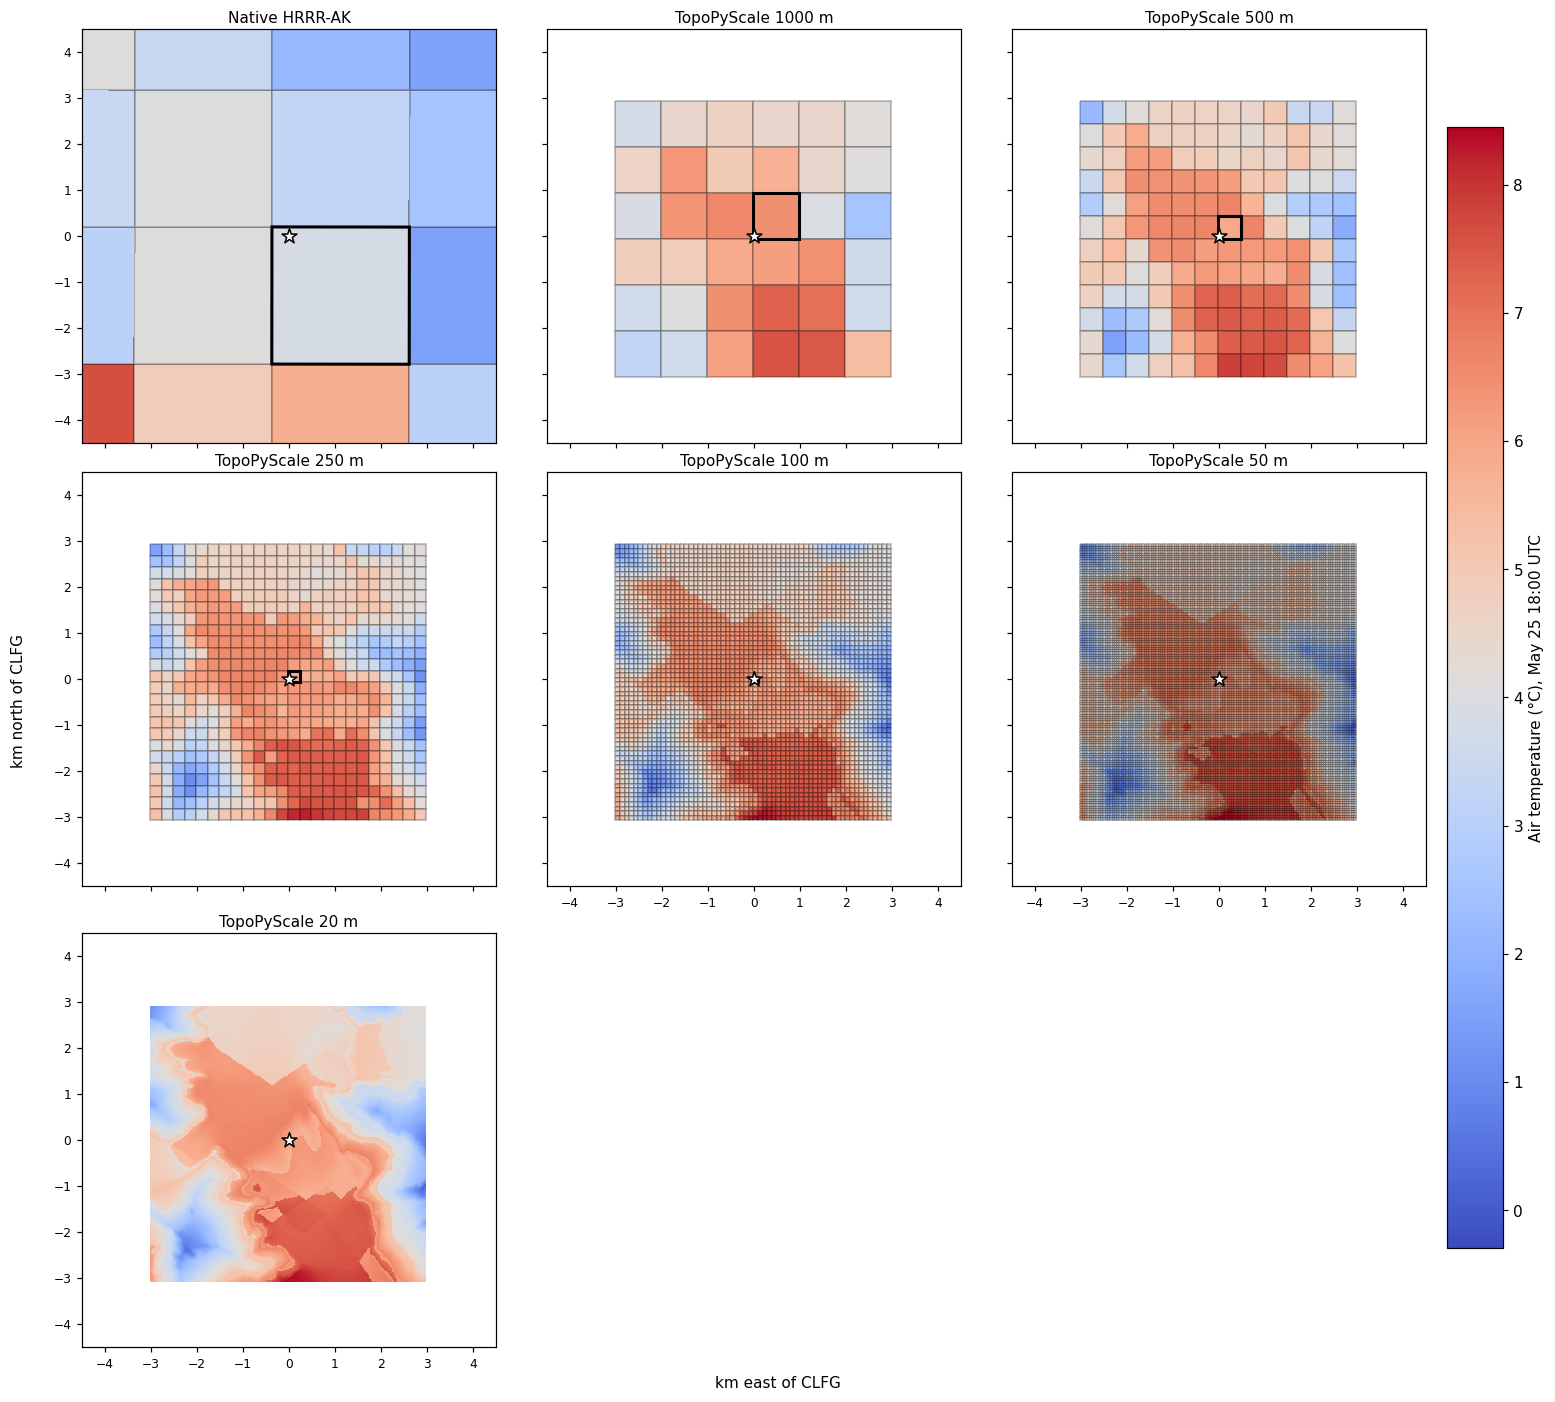

In [3]:
hour = pd.Timestamp(f"{year}-05-25T18:00")
finished = [m for m in terrain_grids if (project / f"{m}m/forcing.nc").exists()]
if finished and surface_path.exists():
    with xr.open_dataset(surface_path) as raw:
        raw_t = raw.temp.sel(time=hour).values - 273.15
    temperature_maps = [(*panels[0][:3], raw_t)]
    for m in finished:
        path = project / f"{m}m/forcing.nc"
        cell_ids, panel = terrain_grids[m], panels[available.index(m)+1]
        with xr.open_dataset(path) as forcing:
            t = forcing.t.sel(time=hour).values - 273.15
        grid = np.full(cell_ids.shape, np.nan)
        active = cell_ids >= 0
        grid[active] = t[cell_ids[active]]
        temperature_maps.append((*panel[:3], grid))
    plot_maps(temperature_maps, f"Air temperature (°C), {hour:%b %d %H:%M} UTC", "coolwarm")
else:
    print("Waiting for the annual forcing files.")


## CLFG satellite imagery and model grids

The same Esri World Imagery scene underlies each grid. The pink marker shows CLFG and the yellow outline marks its containing cell. The glacier overview shows the grid in context near Mendenhall and Herbert glaciers. The close-up is centered on CLFG and spans the width and height of one native 3 km HRRR-AK cell.

The imagery uses UTM zone 8N and shares the cache with the CLFG satellite notebook. The first run downloads the image if it is absent.

In [4]:
import hashlib
import io
import json
from urllib.parse import urlencode
from urllib.request import urlopen

import matplotlib.patheffects as pe
from PIL import Image

CACHE = folder.parent / "data/basemaps"
UTM = 32608
easting_km, northing_km = east / 1000, north / 1000
image_bbox = (
    np.floor(easting_km) - 6, np.floor(northing_km) - 4,
    np.ceil(easting_km) + 6, np.ceil(northing_km) + 10,
)

service = 'https://services.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer'
params = dict(
    bbox=','.join(str(int(km * 1000)) for km in image_bbox),
    bboxSR=UTM, imageSR=UTM, size=f'{int((image_bbox[2]-image_bbox[0])*100)},{int((image_bbox[3]-image_bbox[1])*100)}',
    format='jpg', f='json',
)
cache_key = hashlib.sha256(urlencode(params).encode()).hexdigest()[:16]
image_path = CACHE / f'esri_{cache_key}.jpg'
metadata_path = CACHE / f'esri_{cache_key}.json'
if not (image_path.is_file() and metadata_path.is_file()):
    with urlopen(f'{service}/export?{urlencode(params)}', timeout=60) as response:
        metadata = json.load(response)
    if 'error' in metadata:
        raise RuntimeError(f'Esri World Imagery export failed: {metadata["error"]}')
    with urlopen(metadata['href'], timeout=60) as response:
        image_bytes = response.read()
    with Image.open(io.BytesIO(image_bytes)) as downloaded:
        downloaded.verify()
    CACHE.mkdir(parents=True, exist_ok=True)
    image_path.write_bytes(image_bytes)
    metadata_path.write_text(json.dumps(metadata, indent=2))

bounds = json.loads(metadata_path.read_text())['extent']
image_extent = (
    (bounds["xmin"] - east) / 1000, (bounds["xmax"] - east) / 1000,
    (bounds["ymin"] - north) / 1000, (bounds["ymax"] - north) / 1000,
)
with Image.open(image_path) as cached:
    imagery = np.asarray(cached.convert('RGB'))

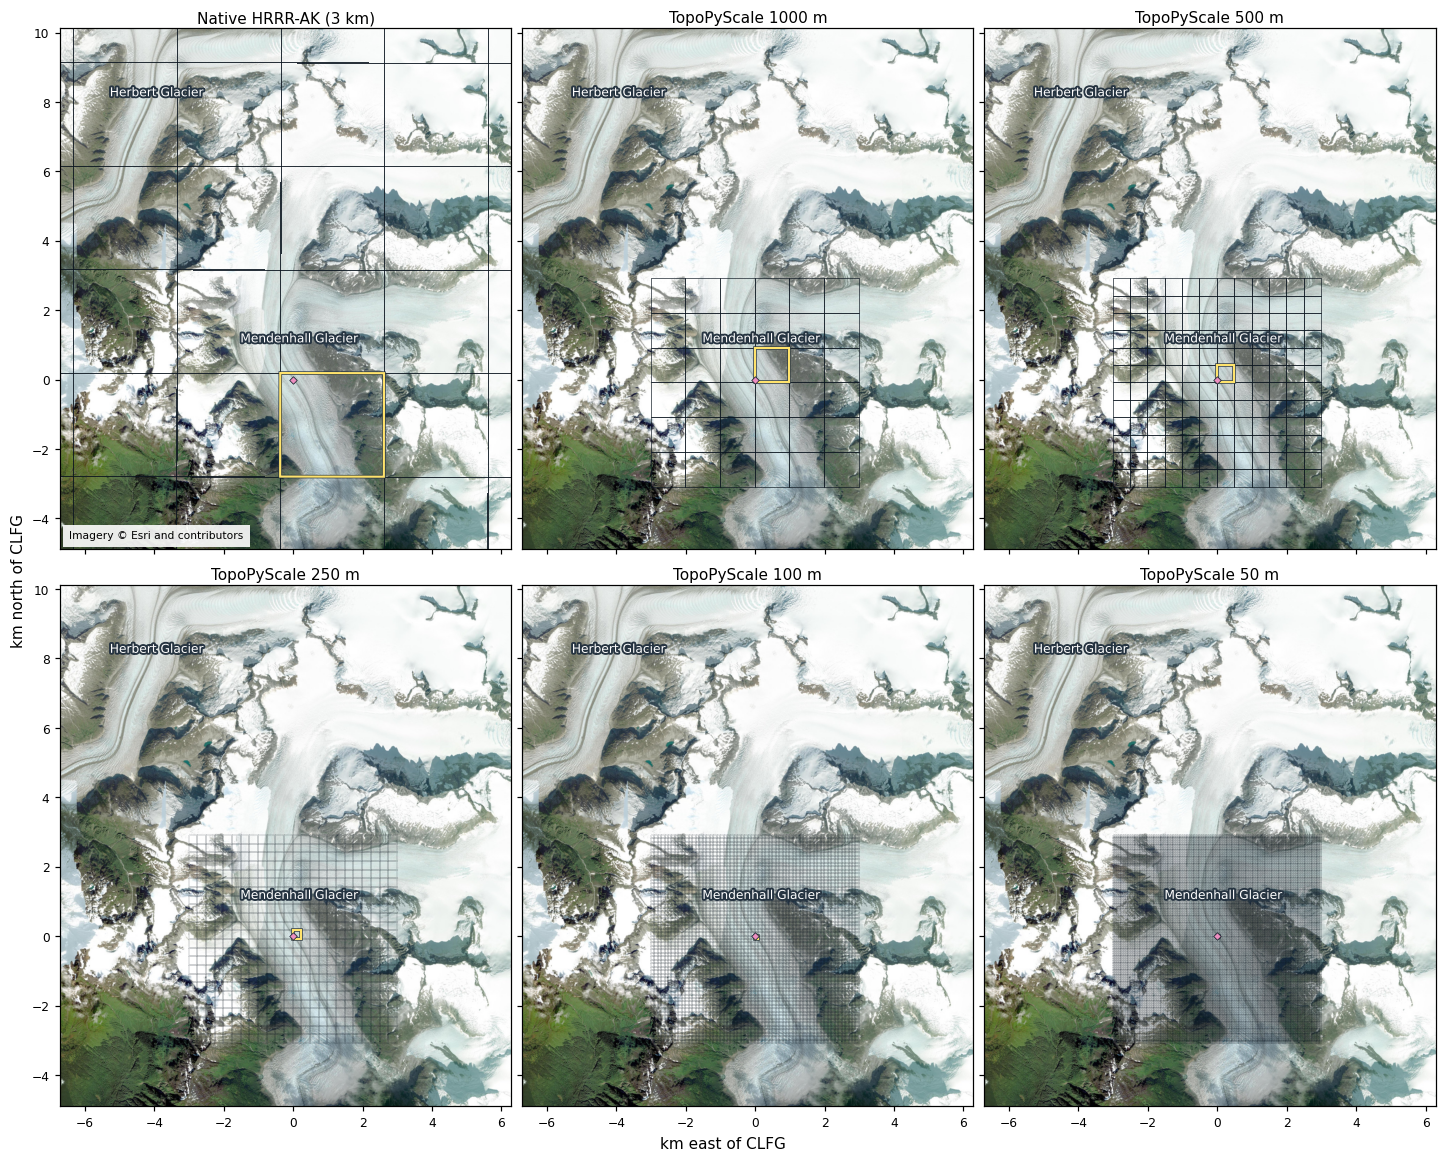

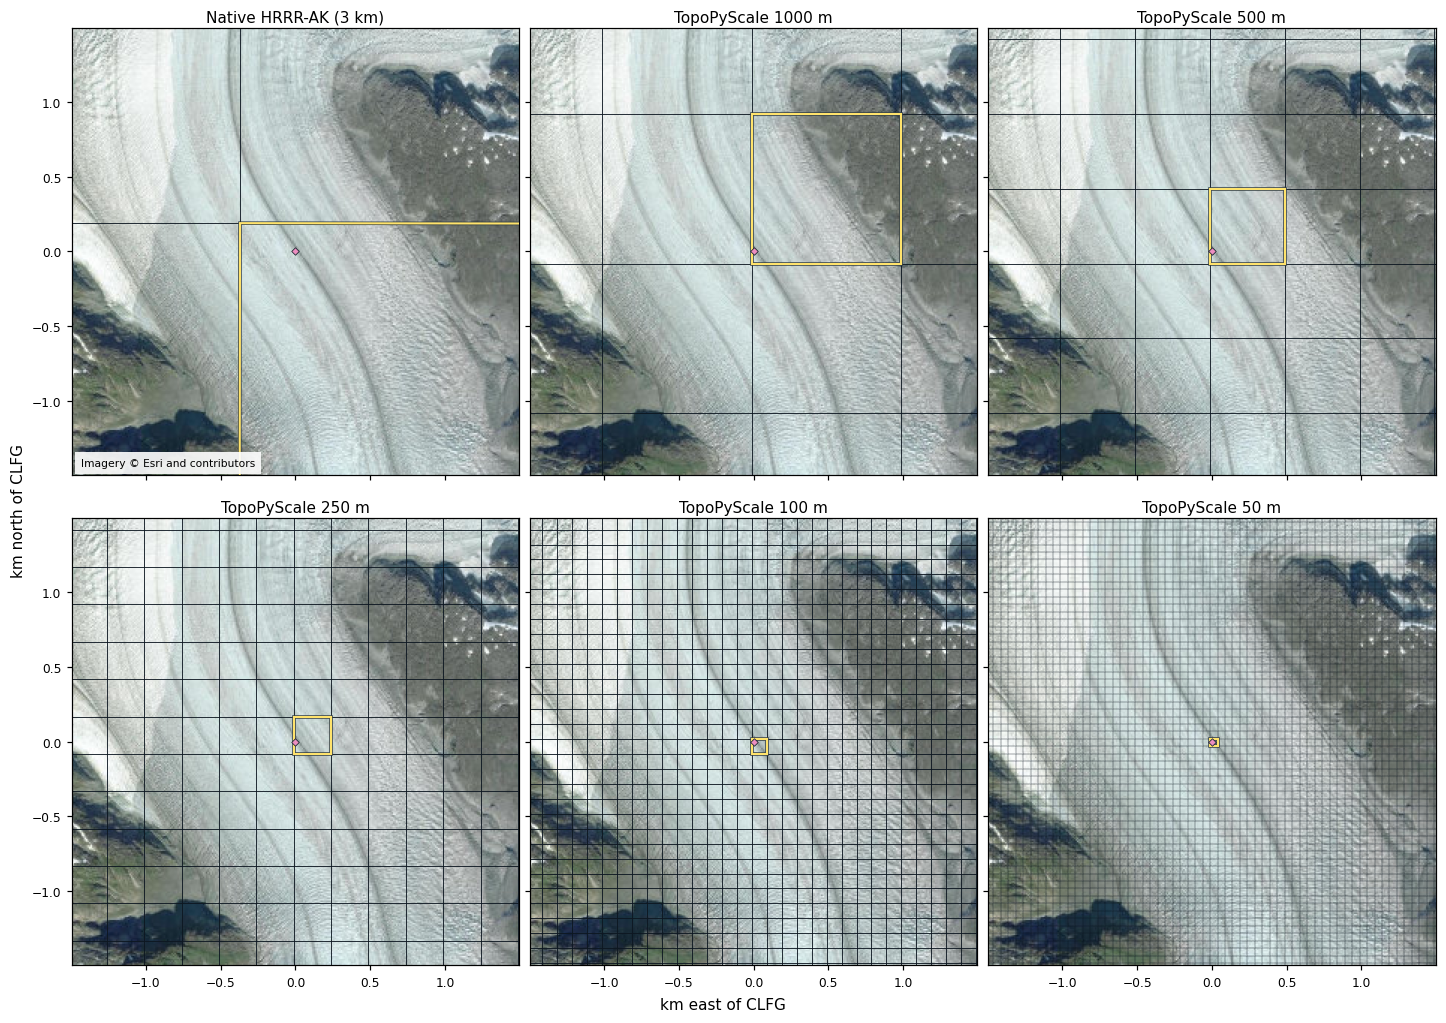

In [5]:
glacier_labels = {
    "Mendenhall Glacier": (-134.538629, 58.5052512),
    "Herbert Glacier": (-(134 + 36/60 + 30/3600), 58 + 34/60 + 9/3600),
}
to_utm = Transformer.from_crs(4326, UTM, always_xy=True)


def plot_satellite_grids(extent, show_glaciers=False):
    items = [panel for panel in panels if elevations.loc[panel[0], "resolution_m"] != 20]
    fig, axes = map_panels(items, extent)
    west, east_limit, south, north_limit = extent
    for ax, (label, x, y, _) in zip(axes, items):
        ax.imshow(imagery, extent=image_extent, origin="upper")
        xx, yy = (x - east) / 1000, (y - north) / 1000
        # Include cells whose bounding boxes intersect the view.
        corners = np.s_[:-1, :-1], np.s_[1:, :-1], np.s_[:-1, 1:], np.s_[1:, 1:]
        x_corners = [xx[corner] for corner in corners]
        y_corners = [yy[corner] for corner in corners]
        in_view = (
            (np.minimum.reduce(x_corners) < east_limit)
            & (np.maximum.reduce(x_corners) > west)
            & (np.minimum.reduce(y_corners) < north_limit)
            & (np.maximum.reduce(y_corners) > south)
        )
        rows, cols = np.nonzero(in_view)
        if rows.size:
            row_slice = slice(rows.min(), rows.max() + 2)
            col_slice = slice(cols.min(), cols.max() + 2)
            shape = (rows.max() - rows.min() + 1, cols.max() - cols.min() + 1)
            spacing = elevations.loc[label, "resolution_m"]
            dense = spacing <= 250 if show_glaciers else spacing <= 50
            grid = ax.pcolormesh(
                xx[row_slice, col_slice], yy[row_slice, col_slice], np.zeros(shape),
                edgecolors=(.05, .09, .13, .10 if dense else .65),
                linewidth=.08 if dense else .45, zorder=2,
            )
            grid.set_array(None)
            grid.set_facecolor("none")
        outline_site_cell(ax, label, xx, yy, edgecolor="#ffe36c", linewidth=1.4, zorder=3,
                          path_effects=[pe.withStroke(linewidth=2.3, foreground="#263441")])
        if show_glaciers:
            for name, (longitude, latitude) in glacier_labels.items():
                gx, gy = to_utm.transform(longitude, latitude)
                ax.text((gx - east) / 1000, (gy - north) / 1000, name,
                        ha="center", va="center", color="white", fontsize=8, zorder=4,
                        path_effects=[pe.withStroke(linewidth=2.5, foreground="#263441")])
        ax.scatter(0, 0, marker="D", s=12, color="#ed8ec0",
                   edgecolor="#15212c", linewidth=.5, zorder=5)
        ax.set_title(label if label != "Native HRRR-AK" else "Native HRRR-AK (3 km)",
                     fontsize=10, pad=4)
    axes[0].text(.02, .02, "Imagery © Esri and contributors", transform=axes[0].transAxes,
                 fontsize=7, bbox=dict(fc="white", ec="none", alpha=.9), zorder=6)
    plt.show()


plot_satellite_grids(image_extent, show_glaciers=True)
# Center the projected width and height of the native cell on CLFG.
native_label, native_x, native_y, _ = panels[0]
row, col = elevations.loc[native_label, ["row", "col"]].astype(int)
cell_x = (native_x[row:row + 2, col:col + 2] - east) / 1000
cell_y = (native_y[row:row + 2, col:col + 2] - north) / 1000
half_width, half_height = np.ptp(cell_x) / 2, np.ptp(cell_y) / 2
plot_satellite_grids((-half_width, half_width, -half_height, half_height))

The 20 m TopoPyScale grid is omitted from both satellite figures.

## CLFG site and grid-cell elevations

The black bar is the CLFG site reference sampled from the 2 m ArcticDEM. Grid-bar labels give the elevation difference from that reference in meters (grid minus reference).

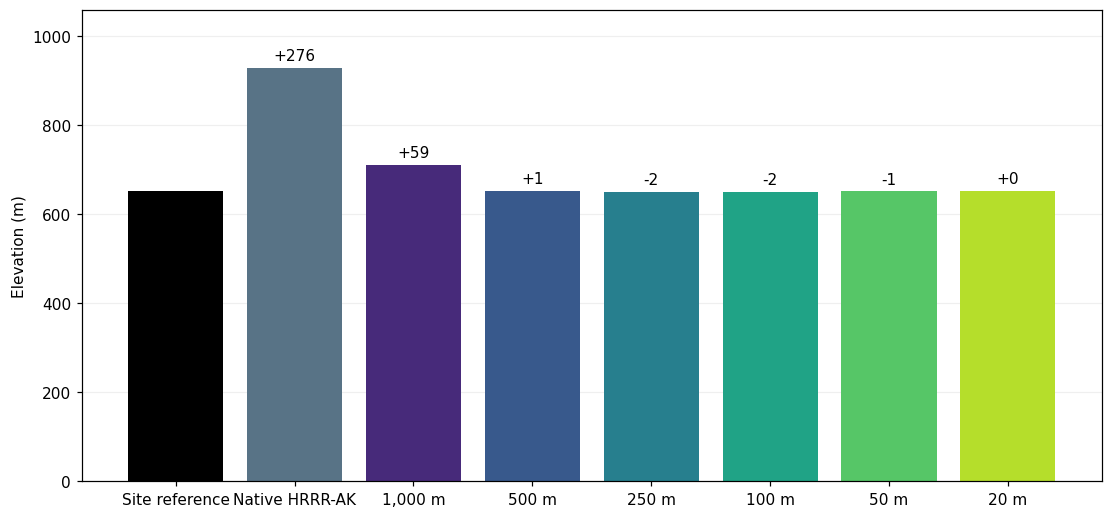

In [6]:
grid_labels = elevations.index.tolist()
grid_elevations = elevations.elevation_m.to_numpy()
differences = elevations.cell_minus_reference_m.to_numpy()
labels = ["Site reference", "Native HRRR-AK", *(f"{m:,} m" for m in available)]
# Match the 1,000 m to 20 m Viridis palette in icefield_clfg_timeseries.ipynb.
colors = dict(zip(
    (f"TopoPyScale {m} m" for m in RESOLUTIONS),
    plt.cm.viridis(np.linspace(.12, .89, len(RESOLUTIONS))),
))
colors["Native HRRR-AK"] = "#587386"
fig, ax = plt.subplots(figsize=(10, 4.6), layout="constrained")
bars = ax.bar(labels, [reference, *grid_elevations],
              color=["black", *(colors[label] for label in grid_labels)])
ax.bar_label(bars, labels=["", *(f"{delta:+.0f}" for delta in differences)], padding=3)
ax.set(ylabel="Elevation (m)")
ax.set_ylim(0, 1.14 * max(reference, np.nanmax(grid_elevations)))
ax.grid(axis="y", alpha=.2)
ax.set_axisbelow(True)
plt.show()